# SAM2 Amazon Mine Detection Inference Demo

This code shows how you can run our finetuned SAM2 model on tiles of rainforest to segment which pixels in the image are mines.

It takes in RGB .png images as input and returns a labelled image representing which areas are mines as output.

You should be able to run inference on a T4 GPU.

## Step 0 - Setup Google Colab (If Necessary)

In [2]:
# Connect to drive from colab. You will need to accept the prompt.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Step 1 - Configuration
Edit these lines for the setup of your choosing.

In [3]:
# To do this for a shared folder you need to add this folder as a shortcut into your MyDrive folder
# CHANGE THESE LOCATIONS TO APPROPRIATE DIRECTORIES
ROOT_IMAGE_FOLDER = "/content/drive/MyDrive/GeoCompassSegmentations"
MODEL_DIRECTORY = ROOT_IMAGE_FOLDER + "/Colab_Notebooks/models/SAM_model_96_px_final.pth"
# Change this to true if you want to use .tif files with datamasks to set which
# pixels are valid or not. You may want to do this if you have a prior for where
# gold mine pixels are located from an object detection model.
USE_MASKS = False

## Step 2 - Download Base SAM2 Model
We will be using SAM2_hiera_small. We'll also set our root folder for our

In [4]:
!git clone https://github.com/facebookresearch/sam2.git
%cd ./sam2
!pip install -e .
!./checkpoints/download_ckpts.sh

Cloning into 'sam2'...
remote: Enumerating objects: 1070, done.
remote: Total 1070 (delta 0), reused 0 (delta 0), pack-reused 1070 (from 1)
Receiving objects: 100% (1070/1070), 128.11 MiB | 42.03 MiB/s, done.
Resolving deltas: 100% (381/381), done.
/content/sam2
Obtaining file:///content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 kB 9.2 MB/s eta 0:00:00
  Building editable for SAM-2 (pyproject.toml) ... done
  Created wheel for SAM-2: filename=sam_2-1.0-0.editable-cp312-cp312-linux_x86_64.whl size=13852 sha256=483eb1bb7ccde245e73d5646e3e3f8b485cb60868a5e5e42d7f50ce3ecc12fb1
  Stored in directory: /tmp/pip-ephem-wheel-cache-fni8nq_9/wheels/9e/fa/

## 2.1 - Load RasterIO to handle input geotiff images

In [5]:
!pip install rasterio
import rasterio

## Step 3 - Load Finetuned Model on top of SAM2 Base model

In [6]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import re
import torch
from pathlib import Path
import os

In [7]:
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor
device = "cuda"

# Initialize sam model
sam2_checkpoint = "sam2.1_hiera_small.pt" # path to model weight
finetuned = MODEL_DIRECTORY
model_cfg = "configs/sam2.1/sam2.1_hiera_s.yaml" #  model config
sam2_model = build_sam2(model_cfg, sam2_checkpoint, device=device) # load model

# Load your fine-tuned weights
state = torch.load(finetuned, map_location="cpu")
sam2_model.load_state_dict(state, strict=False)
sam2_model.eval()

# Wrap with predictor
predictor = SAM2ImagePredictor(sam2_model)

## Step 4 - Load Images and Masks (If Available)
Images should be RGB pngs. Masks should be the geotiff dataset_mask(), setting which pixels are valid and invalid for segmentation.

In [17]:
def get_bounding_box(mask):
  rows, cols = np.where(mask>0)
  if len(rows) == 0:
        return None
  return np.array([np.min(cols), np.min(rows), np.max(cols), np.max(rows)])

def evaluate_sam2(loader, predictor, max_examples=None):
    pred_labels = {}
    count = 0
    total_pred_area = 0
    total_area = 0

    # Iterate through batches
    for batch_idx, batch_data in enumerate(loader):
        # Stop if we have reached the limit
        if max_examples is not None and count >= max_examples:
            break

        # Adjust unpacking based on your dataloader structure
        image = batch_data['rgb']
        if USE_MASKS:
            valid_mask = batch_data['mask']

        # Check limit again inside the batch loop
        if max_examples is not None and count >= max_examples:
            break

        # A. Preprocess Image (C,H,W -> H,W,C and uint8 0-255)
        img_np = image.transpose(1, 2, 0)

        # Denormalize if necessary
        if img_np.max() <= 1.0:
            img_np = (img_np * 255).astype(np.uint8)
        else:
            img_np = img_np.astype(np.uint8)

        predictor.set_image(img_np)

        # B. Prepare Prompt
        box_prompt = None
        if USE_MASKS:
            valid_mask_np = valid_mask.astype(np.uint8)
            box = (valid_mask_np > 0).astype(np.uint8)
            box_prompt = get_bounding_box(box)
        else:
            box = np.ones(img_np.shape[0:2])
            box_prompt = get_bounding_box(box)

        if box_prompt is None:
            continue

        # C. Predict
        labels, scores, _ = predictor.predict(
            box=box_prompt,
            multimask_output=True
        )

        # D. Calculate IoU
        best_idx = np.argmax(scores)
        pred_label = (labels[best_idx] > 0.0).astype(np.uint8)
        pred_labels[batch_idx] = pred_label

        count += 1
        if count % 50 == 0:
            print(f"Processed {count} images...")

    return pred_labels


4.1 Create Dataset


In [18]:
# Now we make a custom dataloader for images on disk
from torch.utils.data import Dataset
class FullImageDataset(Dataset):
    def __init__(self, base_dir):
        # Replace this with the folders your rgb, labels, and tiff images are in.
        # We assume that there are consistent numbered prefixes in each of these folders so we can match rgb images and masks
        self.rgb_dir = base_dir + "/training_images_RGBs"
        if USE_MASKS:
            self.tiff_dir = base_dir + "/training_images_masked"
            self.tiff_filenames = [os.path.join(self.tiff_dir,f) for f in os.listdir(self.tiff_dir) if os.path.isfile(os.path.join(self.tiff_dir, f))]
            self.tiff_filenames.sort()
        self.rgb_filenames = [os.path.join(self.rgb_dir,f) for f in os.listdir(self.rgb_dir) if os.path.isfile(os.path.join(self.rgb_dir, f))]
        self.rgb_filenames.sort()
        self.length = len(os.listdir(self.rgb_dir))
        return

    def __len__(self):
        return self.length

    def __getitem__(self, i):
        res = dict()

        rgb_file = self.rgb_filenames[i]
        if USE_MASKS:
            tiff_file = self.tiff_filenames[i]
            with rasterio.open(tiff_file) as src:
                red = src.read(4).astype(np.float32)
                nir = src.read(8).astype(np.float32)
                label_nvdi = (nir - red) / (nir + red + 1e-6) < 0.5
                label_mask = src.dataset_mask().astype(np.float32) / 255.0
        with rasterio.open(rgb_file) as src:
            arr = src.read().astype(np.float32) / 255.0
        res['rgb'] = arr
        res['rgb_filename'] = rgb_file
        if USE_MASKS:
            res['mask'] = label_mask
            res['nvdi'] = label_nvdi
        return res

Label all images with SAM2. This may take a while depending on how large the dataset is.

In [19]:
full_image_loader = FullImageDataset(ROOT_IMAGE_FOLDER)
# I changed this to evaluate our models on full images - Michael
predicted_labels = evaluate_sam2(full_image_loader, predictor)

(384, 384)
(96, 96)
(384, 384)
(480, 480)
(144, 144)
(240, 240)
(432, 432)
(144, 144)
(144, 144)
(144, 144)
(96, 96)
(432, 432)
(144, 144)
(240, 240)
(96, 96)
(96, 96)
(96, 96)
(96, 96)
(144, 144)
(96, 96)
(96, 96)
(96, 96)
(192, 192)
(240, 240)
(240, 240)
(144, 144)
(96, 96)
(96, 96)
(96, 96)
(192, 192)
(96, 96)
(96, 96)
(96, 96)
(576, 576)
(96, 96)
(96, 96)
(144, 144)
(96, 96)
(192, 192)
(288, 288)
(240, 240)
(96, 96)
(192, 192)
(336, 336)
(192, 192)
(96, 96)
(96, 96)
(144, 144)
(336, 336)
(480, 480)
Processed 50 images...
(96, 96)
(96, 96)
(96, 96)
(528, 528)
(192, 192)
(96, 96)
(144, 144)
(96, 96)
(96, 96)
(480, 480)
(96, 96)
(96, 96)
(144, 144)
(96, 96)
(192, 192)
(192, 192)
(192, 192)
(96, 96)
(144, 144)
(144, 144)
(240, 240)
(144, 144)
(144, 144)
(96, 96)
(576, 576)
(96, 96)
(144, 144)
(96, 96)
(144, 144)
(96, 96)
(96, 96)
(96, 96)
(240, 240)
(96, 96)
(96, 96)
(144, 144)
(96, 96)
(96, 96)
(144, 144)
(96, 96)
(144, 144)
(144, 144)
(480, 480)
(96, 96)
(240, 240)
(96, 96)
(96, 96)


## Step 5 - View and Save Images


In [20]:
def plot_image(rgb, label, mask=None, save_path=None, img_no=1):
    rgb = rgb.transpose(1, 2, 0)
    if mask:
        label = label*mask

    fig, axs = plt.subplots(
        1, 2,
        figsize=(10, 5),
        constrained_layout=True
    )
    # Original image
    axs[0].imshow(rgb)
    axs[0].set_title("Original Image")
    axs[0].axis("off")

    # Image with predicted labels
    axs[1].imshow(rgb)
    axs[1].imshow(label, alpha=0.3)
    axs[1].set_title("Predicted Labels")
    axs[1].axis("off")
    fig.suptitle("SAM2 Model Outputs", fontsize=14)
    if save_path is None:
        plt.show()
    else:
        plt.savefig(f"{save_path}/{img_no}.png", bbox_inches="tight")

    plt.close()

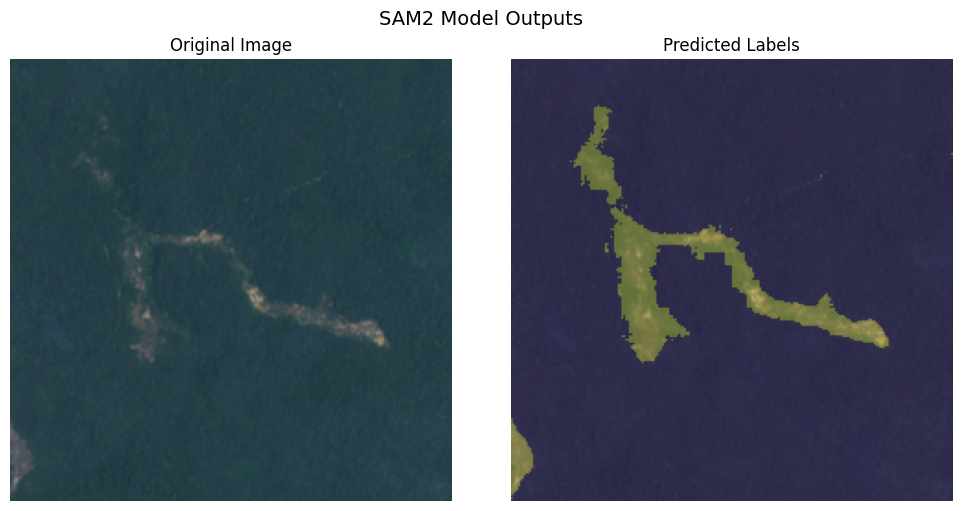

/content/drive/MyDrive/GeoCompassSegmentations/training_images_RGBs/poly014area227.70S2L1C_clear0.75_2023-07-01_2023-12-31.png


In [21]:
image_index = 13
rgb = full_image_loader[image_index]['rgb']
mask=None
if USE_MASKS:
    mask = full_image_loader[image_index]['mask']
label = predicted_labels[image_index]

plot_image(rgb, label, mask=mask, img_no=image_index)

# If you want to save any of these images, an image of the labels are in the label variable
# You can use the original filename to make a similar output file.
print(full_image_loader[image_index]['rgb_filename'])